In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.feature_selection import SelectKBest, chi2, SelectFromModel
from sklearn.decomposition import PCA

# MODELS
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

import pickle

In [2]:
train = pd.read_csv("Data\Training.csv")
test = pd.read_csv("Data\Testing.csv")

In [3]:
train.head()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN


In [4]:
train.shape

(4920, 134)

In [7]:
train.describe()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,Unnamed: 133
count,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,...,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,4920.000000,0.0
mean,0.137805,0.159756,0.021951,0.045122,0.021951,0.162195,0.139024,0.045122,0.045122,0.021951,...,0.021951,0.021951,0.023171,0.023171,0.023171,0.023171,0.023171,0.023171,0.023171,NaN
std,0.344730,0.366417,0.146539,0.207593,0.146539,0.368667,0.346007,0.207593,0.207593,0.146539,...,0.146539,0.146539,0.150461,0.150461,0.150461,0.150461,0.150461,0.150461,0.150461,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN


In [8]:
test.head()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,0,0,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Allergy
2,0,0,0,0,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,GERD
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Chronic cholestasis
4,1,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,Drug Reaction


In [9]:
test.shape

(42, 133)

In [10]:
test.describe()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,pus_filled_pimples,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze
count,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,...,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000
mean,0.166667,0.190476,0.023810,0.047619,0.023810,0.166667,0.142857,0.047619,0.047619,0.023810,...,0.023810,0.023810,0.023810,0.047619,0.023810,0.023810,0.023810,0.023810,0.047619,0.023810
std,0.377195,0.397437,0.154303,0.215540,0.154303,0.377195,0.354169,0.215540,0.215540,0.154303,...,0.154303,0.154303,0.154303,0.215540,0.154303,0.154303,0.154303,0.154303,0.215540,0.154303
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
if "Unnamed: 133" in train.columns:
    train.drop("Unnamed: 133", axis=1, inplace=True)

In [13]:
# DROP UNWANTED SYMPTOMS
def clean_df(df):
    drop_cols = [
        'fluid_overload','weight_gain','cold_hands_and_feets','anxiety',
        'irregular_sugar_level','yellow_urine','acute_liver_failure',
        'swelling_of_stomach','drying_and_tingling_lips',
        'continuous_feel_of_urine','internal_itching','polyuria',
        'mood_swings','receiving_unsterile_injections','stomach_bleeding',
        'prominent_veins_on_calf','loss_of_smell','throat_irritation',
        'redness_of_eyes','sinus_pressure','runny_nose',
        'pain_during_bowel_movements','pain_in_anal_region','cramps',
        'bruising','enlarged_thyroid','brittle_nails','swollen_extremeties',
        'slurred_speech','distention_of_abdomen','fluid_overload.1',
        'skin_peeling','silver_like_dusting','small_dents_in_nails',
        'blister','red_sore_around_nose','bloody_stool',
        'swollen_blood_vessels','hip_joint_pain','painful_walking',
        'spinning_movements','altered_sensorium','toxic_look_(typhos)'
    ]
    return df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")

train = clean_df(train)
test = clean_df(test)

In [14]:
# SPLIT X, y
X = train.drop("prognosis", axis=1)
y = train["prognosis"]

X_test = test.drop("prognosis", axis=1)
y_test = test["prognosis"]

le = LabelEncoder()
y = le.fit_transform(y)
y_test = le.transform(y_test)


In [16]:
# TRAIN/VAL SPLIT
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## *MODEL 1 — SVM (Scaling + SelectKBest (chi2))*

In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler_svm = MinMaxScaler()   # chi2 requires non-negative values
X_train_svm = scaler_svm.fit_transform(X_train)
X_val_svm = scaler_svm.transform(X_val)

selector_svm = SelectKBest(chi2, k=45)
X_train_svm = selector_svm.fit_transform(X_train_svm, y_train)
X_val_svm = selector_svm.transform(X_val_svm)

svm = SVC(C=2, gamma="scale", kernel="rbf", probability=True)
svm.fit(X_train_svm, y_train)
y_pred_svm = svm.predict(X_val_svm)

## *MODEL 2 — RANDOM FOREST (NO SCALING) — uses all features*

In [20]:
rf = RandomForestClassifier(
    n_estimators=350,
    max_depth=None,
    min_samples_split=2,
    random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_val)

## *MODEL 3 — KNN (Scaling + PCA Dimensionality Reduction)*

In [21]:
scaler_knn = StandardScaler()
X_train_knn = scaler_knn.fit_transform(X_train)
X_val_knn = scaler_knn.transform(X_val)

pca = PCA(n_components=30)
X_train_knn = pca.fit_transform(X_train_knn)
X_val_knn = pca.transform(X_val_knn)

knn = KNeighborsClassifier(n_neighbors=7, metric="euclidean")
knn.fit(X_train_knn, y_train)
y_pred_knn = knn.predict(X_val_knn)

## *MODEL 4 — GRADIENT BOOSTING (SelectFromModel Feature Selection)*

In [24]:
# ===============================================================

# Force numpy arrays (no column names, no warnings)
X_train_np = X_train.to_numpy()
X_val_np = X_val.to_numpy()

temp_model = GradientBoostingClassifier()
temp_model.fit(X_train_np, y_train)

selector_gb = SelectFromModel(temp_model, prefit=True, threshold="median")

X_train_gb = selector_gb.transform(X_train_np)
X_val_gb = selector_gb.transform(X_val_np)

gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3
)
gb.fit(X_train_gb, y_train)
y_pred_gb = gb.predict(X_val_gb)

## *EVALUATION FUNCTION*

In [26]:
def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro")
    rec = recall_score(y_true, y_pred, average="macro")
    f1 = f1_score(y_true, y_pred, average="macro")

    print(f"\n{name} PERFORMANCE")
    print("--------------------------------------")
    print(f"Accuracy : {acc*100:.2f}%")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")

    return f1


## *EVALUATE ALL MODELS*

In [27]:
f1_svm = evaluate("SVM", y_val, y_pred_svm)
f1_rf  = evaluate("Random Forest", y_val, y_pred_rf)
f1_knn = evaluate("KNN", y_val, y_pred_knn)
f1_gb  = evaluate("Gradient Boosting", y_val, y_pred_gb)



SVM PERFORMANCE
--------------------------------------
Accuracy : 76.12%
Precision: 0.7520
Recall   : 0.7612
F1 Score : 0.7467

Random Forest PERFORMANCE
--------------------------------------
Accuracy : 100.00%
Precision: 1.0000
Recall   : 1.0000
F1 Score : 1.0000

KNN PERFORMANCE
--------------------------------------
Accuracy : 99.70%
Precision: 0.9973
Recall   : 0.9970
F1 Score : 0.9969

Gradient Boosting PERFORMANCE
--------------------------------------
Accuracy : 96.65%
Precision: 0.9781
Recall   : 0.9665
F1 Score : 0.9692


C:\Users\Asus\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## *SELECT BEST MODEL BY F1 SCORE*

In [31]:
scores = {
    "SVM": f1_svm,
    "RandomForest": f1_rf,
    "KNN": f1_knn,
    "GradientBoosting": f1_gb
}

best_name = max(scores, key=scores.get)
print("\nBEST MODEL:", best_name)


BEST MODEL: RandomForest


## *SAVE THE CORRECT BEST MODEL + TRANSFORMERS USED BY THAT MODEL*

In [32]:
if best_name == "SVM":
    best_model = svm
    pickle.dump(scaler_svm, open("scaler.pkl", "wb"))
    pickle.dump(selector_svm, open("selector.pkl", "wb"))

elif best_name == "RandomForest":
    best_model = rf

elif best_name == "KNN":
    best_model = knn
    pickle.dump(scaler_knn, open("scaler.pkl", "wb"))
    pickle.dump(pca, open("pca.pkl", "wb"))

elif best_name == "GradientBoosting":
    best_model = gb
    pickle.dump(selector_gb, open("selector.pkl", "wb"))

pickle.dump(best_model, open("best_model.pkl", "wb"))
pickle.dump(le, open("label_encoder.pkl", "wb"))
pickle.dump(list(X.columns), open("symptom_list.pkl", "wb"))

print("\nAll files saved successfully!")


All files saved successfully!


In [34]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    shap.initjs()
except Exception:
    pass

# Background for TreeExplainer
background = X_train.copy()

# Build explainer safely
try:
    explainer = shap.TreeExplainer(rf, data=background)
except Exception:
    explainer = shap.Explainer(rf, background)

# Compute shap values for test set
try:
    raw = explainer.shap_values(X_test)
except Exception:
    shap_explanation = explainer(X_test)
    raw = shap_explanation.values

 99%|===================| 1703/1722 [01:02<00:00]        

In [36]:
raw = explainer.shap_values(X_test)

raw_arr = np.array(raw)

print("RAW SHAP shape:", raw_arr.shape)

# ------------------------------------------------
# UNIVERSAL FIX FOR ANY SHAP SHAPE
# ------------------------------------------------
# Case 1: raw is list → pick class 1 or max class
if isinstance(raw, list):
    # If multi-class, pick the class with highest variation
    lens = [np.abs(r).sum() for r in raw]
    best_class = np.argmax(lens)
    shap_vals = raw[best_class]
    print("Selected class (list):", best_class)

# Case 2: raw is ndarray
elif isinstance(raw, np.ndarray):

    # Case A: (samples, classes, features)
    if raw_arr.ndim == 3 and raw_arr.shape[2] == X_test.shape[1]:
        # choose class with highest total |SHAP|
        totals = raw_arr.sum(axis=2).sum(axis=0)
        best_class = np.argmax(totals)
        shap_vals = raw_arr[:, best_class, :]
        print("Selected class (3D A):", best_class)

    # Case B: (samples, weird_dim, features)
    elif raw_arr.ndim == 3 and raw_arr.shape[1] != X_test.shape[1]:
        # collapse dim 1 using mean
        print("Collapsing weird middle dimension:", raw_arr.shape)
        shap_vals = raw_arr.mean(axis=1)

    # Case C: Already 2-D
    else:
        shap_vals = raw_arr

else:
    raise ValueError("Unknown SHAP type")

print("Final SHAP shape:", shap_vals.shape)


100%|===================| 1719/1722 [01:03<00:00]        

RAW SHAP shape: (42, 89, 41)
Final SHAP shape: (42, 89, 41)


In [42]:
raw = np.array(raw)   # raw shape: (42, 89, 41)

samples, features, classes = raw.shape

# get predicted class for each sample
pred_classes = rf.predict(X_test)

# final shap matrix (sample × feature)
shap_vals = np.zeros((samples, features))

# extract SHAP values for predicted class
for i in range(samples):
    shap_vals[i] = raw[i, :, pred_classes[i]]

print("Final SHAP shape:", shap_vals.shape)


Final SHAP shape: (42, 89)


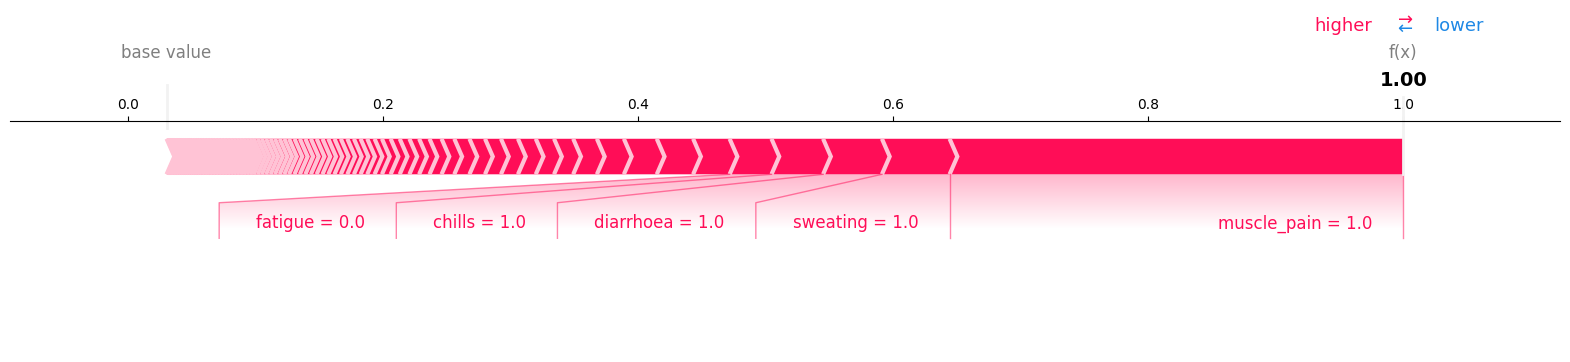

None

In [44]:
# ---------------------------------------
# LOCAL EXPLANATION (FOR SAMPLE 15)
# ---------------------------------------
sample_idx = 15
pred_class = pred_classes[sample_idx]   # predicted disease class index

# Expected value for predicted class
ev = explainer.expected_value[pred_class]

try:
    force_fig = shap.force_plot(
        ev,
        shap_vals[sample_idx],
        X_test.iloc[sample_idx],
        matplotlib=True
    )
    display(force_fig)

except Exception as e:
    print("Force plot unavailable:", e)

    # Fallback: top contributing features
    contribs = pd.Series(
        shap_vals[sample_idx],
        index=X_test.columns
    ).sort_values(key=lambda x: abs(x), ascending=False)

    print("\nTop Contributions:")
    print(contribs.head(10))


In [45]:
# raw → shap_values from explainer
raw = np.array(raw)        # shape: (n_samples, n_features, n_classes)

samples, features, classes = raw.shape
print("Raw:", raw.shape)


Raw: (42, 89, 41)


In [47]:

global_shap = np.zeros((classes, features))

for c in range(classes):
    global_shap[c] = np.abs(raw[:, :, c]).mean(axis=0)

print("global_shap:", global_shap.shape)   # (41 classes, 89 features)


global_shap: (41, 89)


In [48]:
class_wise_top = {}

for c in range(classes):
    top_idx = np.argsort(global_shap[c])[::-1]  # descending
    class_wise_top[c] = [
        (X_test.columns[i], global_shap[c][i])
        for i in top_idx[:10]   # top 10 features per class
    ]


In [49]:
def compare_classes(c1, c2, top=15):
    imp1 = global_shap[c1]
    imp2 = global_shap[c2]

    diff = imp1 - imp2  # how much more important for class1 than class2

    idx = np.argsort(np.abs(diff))[::-1][:top]

    print(f"\nComparison: {le.inverse_transform([c1])[0]} vs {le.inverse_transform([c2])[0]}")

    for i in idx:
        print(f"{X_test.columns[i]:35s} | class {c1}: {imp1[i]:.4f} | class {c2}: {imp2[i]:.4f}")


In [52]:
import matplotlib.pyplot as plt
import shap

def shap_summary_for_class(c):
    plt.figure(figsize=(10, 6))
    shap.summary_plot(
        raw[:, :, c],            # (samples × features)
        X_test,
        feature_names=X_test.columns,
        show=False
    )
    plt.title(f"SHAP Summary - Class {c}: {le.inverse_transform([c])[0]}")
    plt.show()


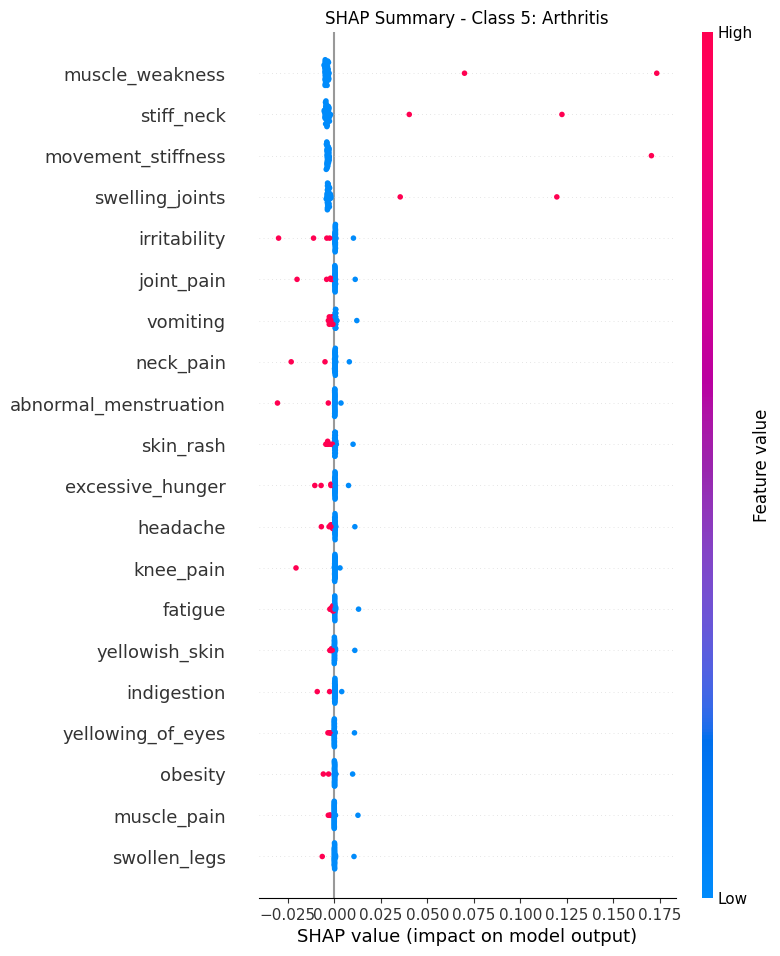

In [55]:
shap_summary_for_class(5)

In [53]:
def shap_dependence_class(c, feature_name):
    feature_idx = X_test.columns.get_loc(feature_name)
    shap.dependence_plot(
        feature_idx,
        raw[:, :, c],       # SHAP values for that class
        X_test,
        feature_names=X_test.columns
    )


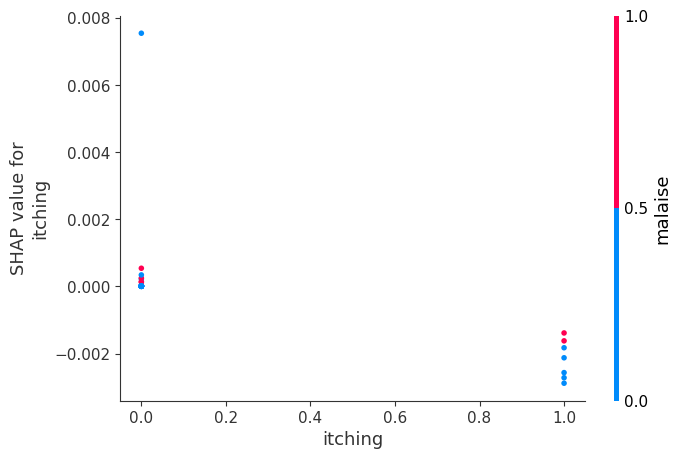

In [56]:
shap_dependence_class(4, "itching")
